# EDA кредитного скоринга

Изучаем обучающую часть того же стратифицированного разбиения 80/20, которое использует пайплайн. Источник — [UCI](https://archive.ics.uci.edu/dataset/350/default).

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

path = Path("data/UCI_Credit_Card.csv")
if not path.exists():
    path = Path("..") / path
df = pd.read_csv(path)
target = "default.payment.next.month"
train, _ = train_test_split(df, test_size=0.2, random_state=42, stratify=df[target])
print(f"Строк: {len(train)}, пропусков: {train.isna().sum().sum()}")
display(train[target].value_counts(normalize=True).rename("доля"))
display(train[["AGE", "LIMIT_BAL", "BILL_AMT1", "PAY_AMT1"]].describe())
for col in ["EDUCATION", "MARRIAGE"]:
    display(train[col].value_counts().sort_index())


Строк: 24000, пропусков: 0


default.payment.next.month
0    0.778792
1    0.221208
Name: доля, dtype: float64

,AGE,LIMIT_BAL,BILL_AMT1,PAY_AMT1
count,24000.000000,24000.000000,24000.00000,24000.000000
mean,35.432625,167364.666667,51100.50225,5623.556292
std,9.195256,129511.313151,73510.03206,16148.316646
min,21.000000,10000.000000,-165580.00000,0.000000
25%,28.000000,50000.000000,3513.75000,1000.000000
50%,34.000000,140000.000000,22330.00000,2100.500000
75%,41.000000,240000.000000,66966.50000,5018.250000
max,75.000000,1000000.000000,964511.00000,873552.000000


EDUCATION
0       12
1     8455
2    11256
3     3903
4       97
5      235
6       42
Name: count, dtype: int64

MARRIAGE
0       47
1    10892
2    12806
3      255
Name: count, dtype: int64

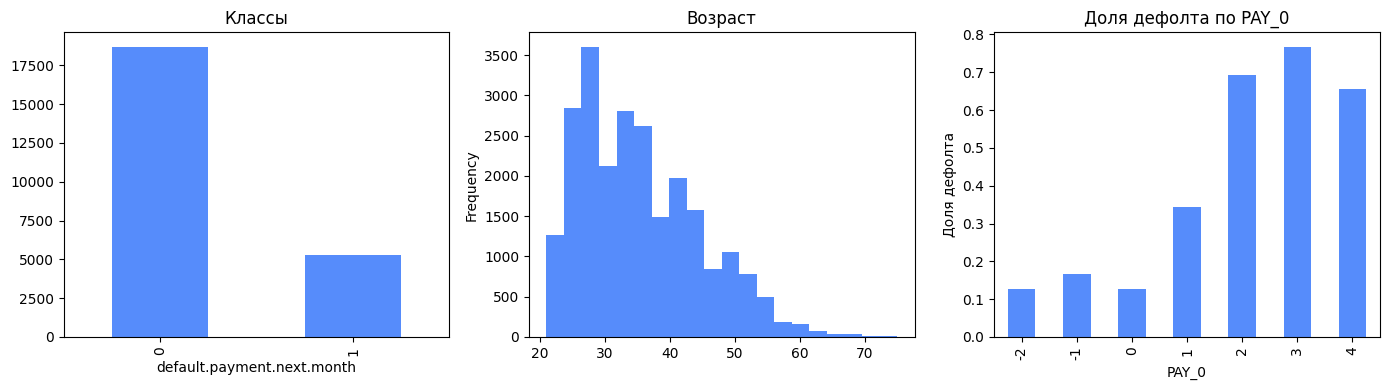

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
train[target].value_counts().sort_index().plot.bar(ax=axes[0], title="Классы")
train["AGE"].plot.hist(ax=axes[1], bins=20, title="Возраст")
groups = train.groupby("PAY_0")[target].agg(["mean", "size"])
groups.query("size >= 30")["mean"].plot.bar(ax=axes[2], title="Доля дефолта по PAY_0")
axes[2].set_ylabel("Доля дефолта")
fig.tight_layout()


Дефолт встречается примерно в 22% записей. В EDUCATION и MARRIAGE есть коды вне основных категорий UCI, поэтому их приводим к «прочим». Отрицательные BILL_AMT сохраняем. Доля дефолта меняется с последней просрочкой, поэтому дополняем исходные статусы максимальной просрочкой и числом месяцев с задержкой.